# 

# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
from aitlas.datasets import OIRDSDataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [8]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
}
dataset = OIRDSDataset(dataset_config)
print(len(dataset))

908


## Show images from the dataset

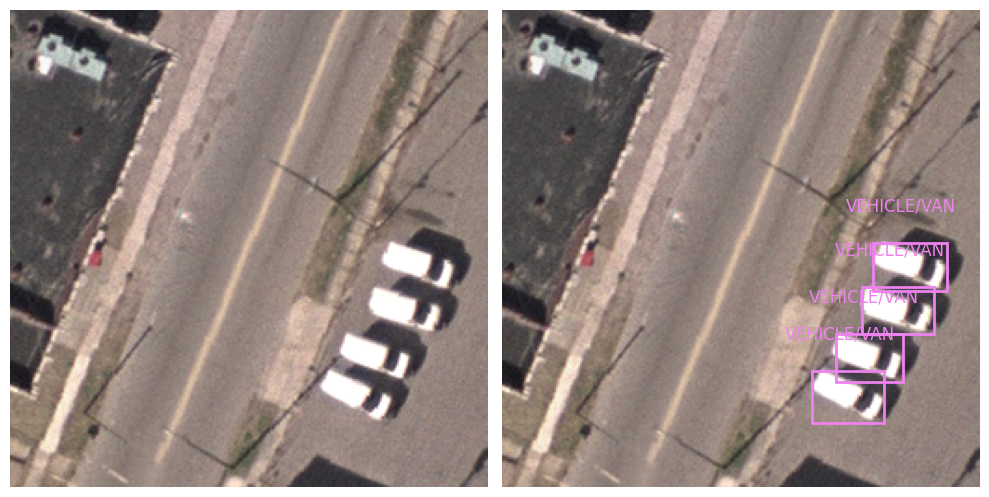

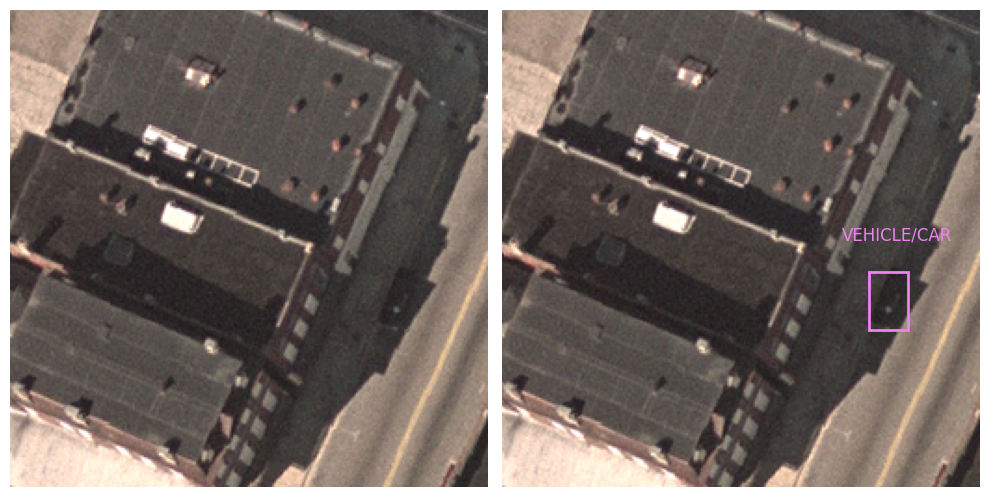

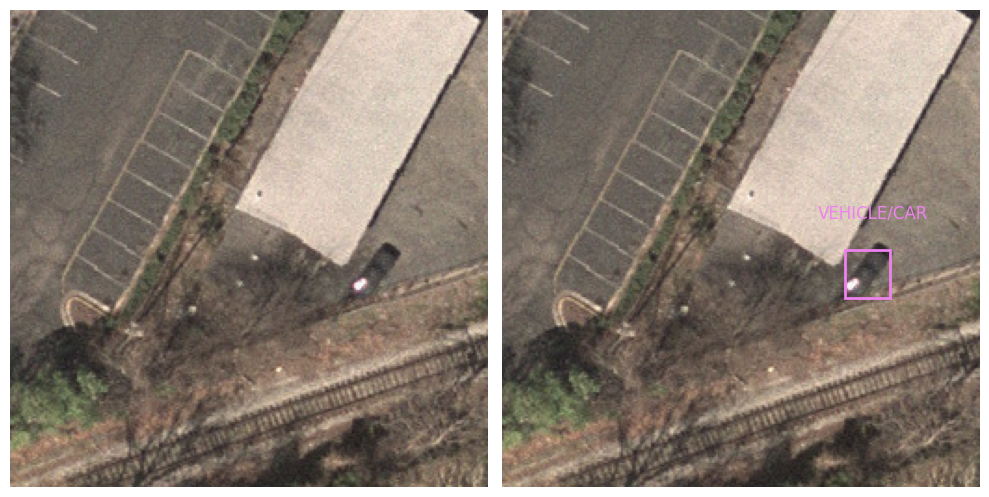

In [9]:
fig1 = dataset.show_image(1)
fig2 = dataset.show_image(2)
fig3 = dataset.show_image(3)

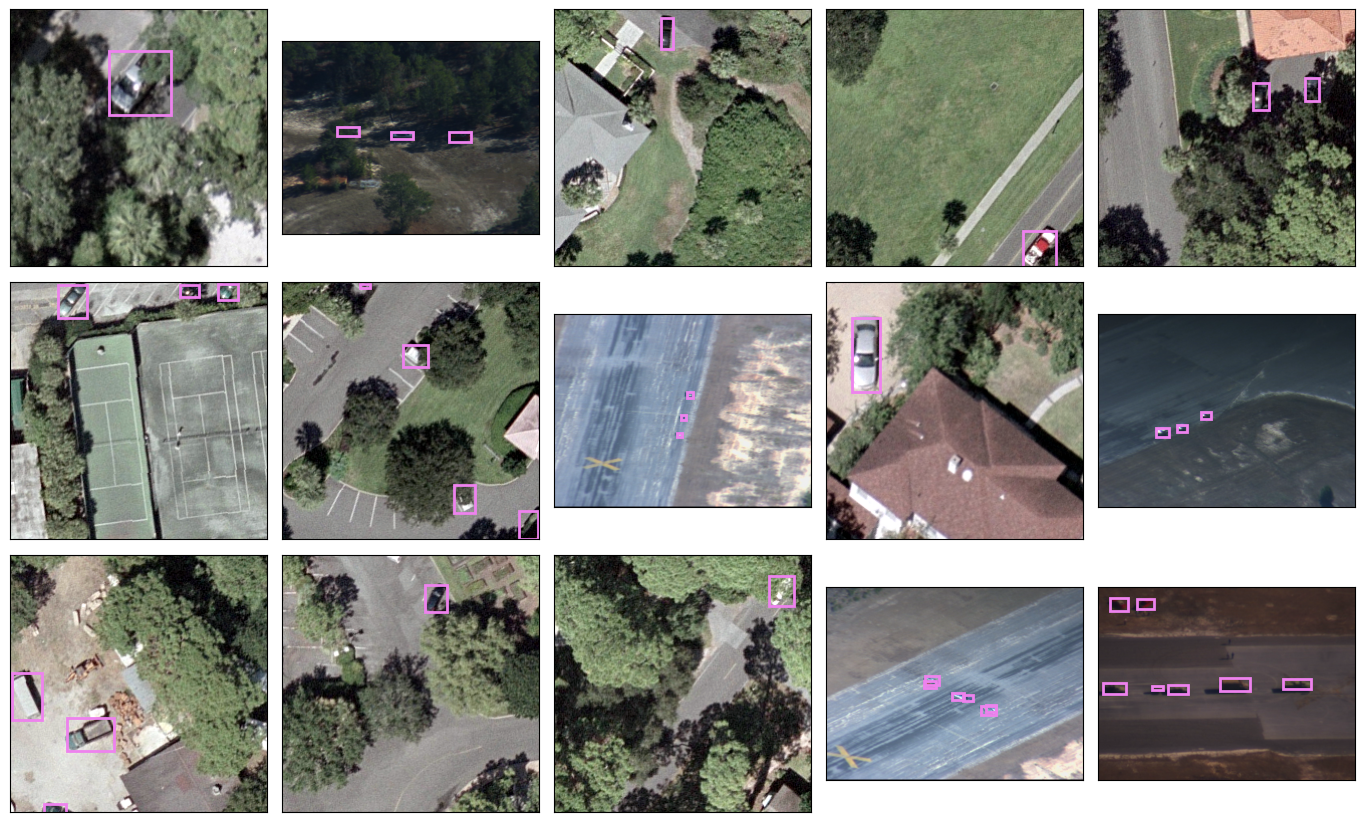

In [4]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [111]:
dataset.data_distribution_table()

,Label,Count
0,VEHICLE/CAR,1020
1,VEHICLE/PICK-UP,352
2,VEHICLE/UNKNOWN,172
3,VEHICLE/VAN,156
4,VEHICLE/TRUCK,96


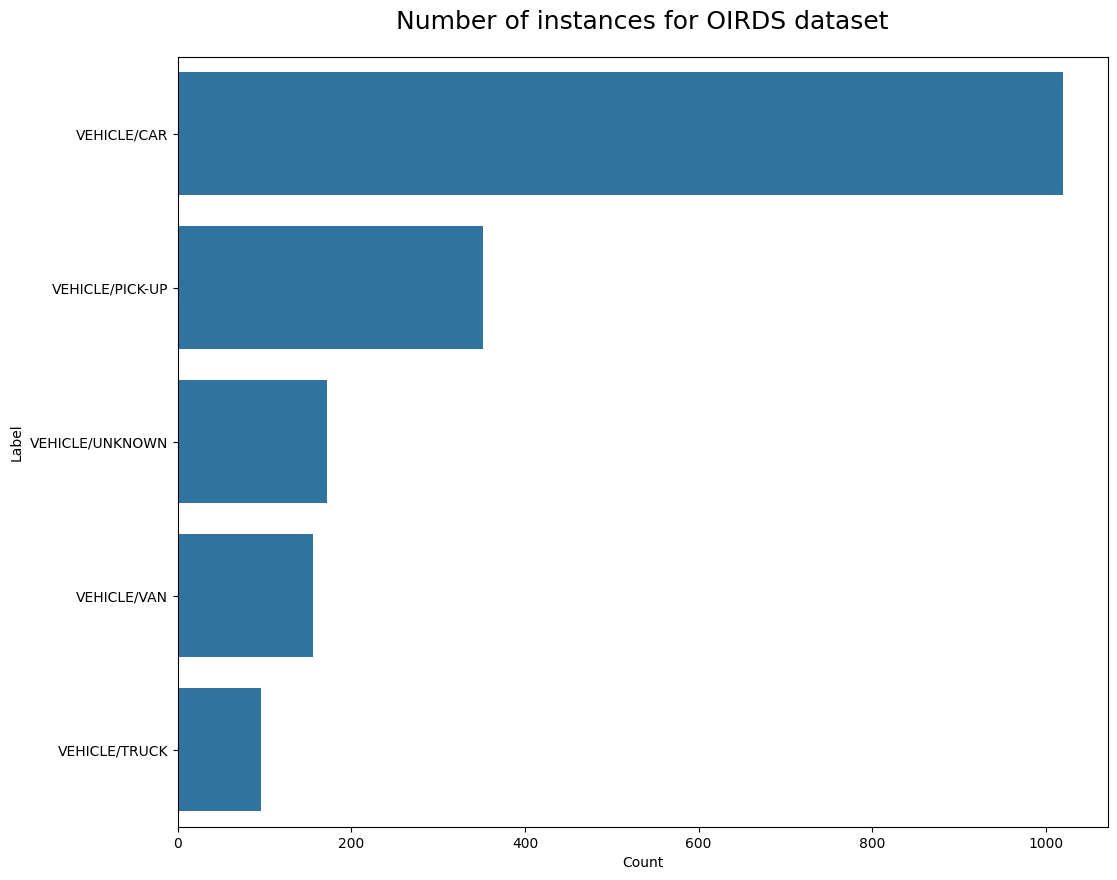

In [112]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [39]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "task": "train",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = OIRDSDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 722


## Setup and create the model for training

In [40]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/oirds/"
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training and validation

In [41]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-22 09:03:06,904 INFO Starting training.
training: 100%|██████████| 91/91 [00:30<00:00,  2.98it/s]
2025-07-22 09:03:37,526 INFO epoch: 1, time: 31, loss:  0.36187
testing on train set: 100%|██████████| 91/91 [00:18<00:00,  5.04it/s]
2025-07-22 09:03:57,897 INFO map:0.11093451082706451, map_50:0.16937695443630219, map_75:0.13415588438510895, map_small:0.09446534514427185, map_medium:0.11416749656200409, map_large:0.20866335928440094, mar_1:0.08970531821250916, mar_10:0.14286258816719055, mar_100:0.14286258816719055, mar_small:0.1466788798570633, mar_medium:0.14382053911685944, mar_large:0.38333332538604736, map_per_class:tensor(0.5451), tensor(0.0084), tensor(0.0012), tensor(0.), tensor(0.), mar_100_per_class:tensor(0.6948), tensor(0.0139), tensor(0.0056), tensor(0.), tensor(0.), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32), tensor(5, dtype=torch.int32)
training: 100%|██████████| 91/91 [00:30<00:00,

## Evaluate the model

In [42]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "task": "val",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = OIRDSDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 104


2025-07-22 09:11:24,508 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar
2025-07-22 09:11:24,867 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 13/13 [00:03<00:00,  3.62it/s]


[{'map': 0.21913549304008484,
  'map_50': 0.3259153962135315,
  'map_75': 0.26451608538627625,
  'map_small': 0.14867201447486877,
  'map_medium': 0.21913552284240723,
  'map_large': -1.0,
  'mar_1': 0.24085906147956848,
  'mar_10': 0.2947397232055664,
  'mar_100': 0.2947397232055664,
  'mar_small': 0.22777777910232544,
  'mar_medium': 0.28855904936790466,
  'mar_large': -1.0,
  'map_per_class': [tensor(0.5089),
   tensor(0.3625),
   tensor(0.0217),
   tensor(0.0470),
   tensor(0.1556)],
  'mar_100_per_class': [tensor(0.5931),
   tensor(0.4714),
   tensor(0.1000),
   tensor(0.0958),
   tensor(0.2133)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32)]}]

## Predictions

2025-07-22 09:12:30,314 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar
2025-07-22 09:12:30,671 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar at epoch 11


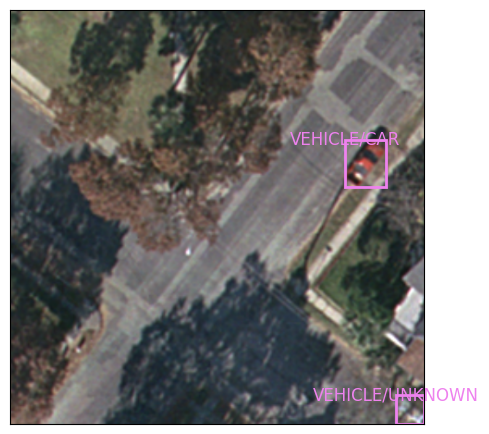

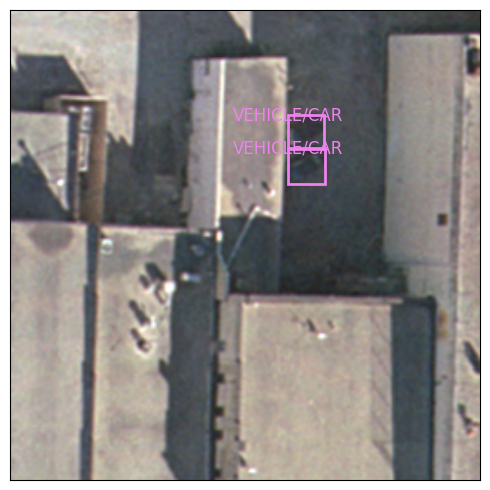

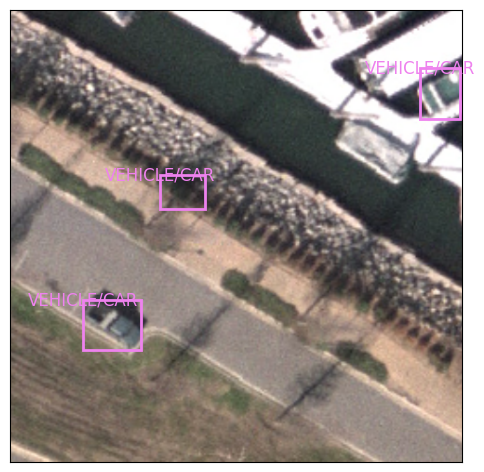

In [43]:
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar"
labels = ["no-data","VEHICLE/CAR", "VEHICLE/PICK-UP", "VEHICLE/UNKNOWN", "VEHICLE/VAN", "VEHICLE/TRUCK"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_19/51764373_1025_6657_1281_6913.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_19/61407638_1281_3329_1537_3585.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_20/33245545_1537_2305_1793_2561.tif')
fig = model.detect_objects(image, labels, transform)